<h1 style="text-align: center; color: white; background-color: #1e86cc; border-radius: 30px; padding: 10px;">COSC3068 - Deep Learning</h1>
<h2 style="text-align: center;">Project 1: Letter Classification</h2>
<h3 style="text-align: center;">Author: Nguyen Gia Khang</h3>
<hr />

> I declare that this submission is my own work. I have acknowledged all sources of code, pretrained models, and other materials, and disclosed any use of AI tools in accordance with the course requirements.

# I. Objective and Approach

This project is a nine-class image classification task involving grayscale patterns that resemble normalised two-dimensional Fourier spectra. The images show centred bright regions, rings, and streaks. The provided dataset contains **30,000** labelled, single-channel images, each measuring **32x32** pixels. Pixel values are represented as floating-point numbers between 0 and 1, and each image has one label in `{a, b, c, d, e, f, g, h, k}`. The task is to use the labelled images to identify the pattern class of a new image and return one of the nine permitted labels. The final classifier will be evaluated on a separate, unseen dataset with the same image format and label set.

# II. Dataset Inspection

## Dataset loading and structure


The given dataset contains 30,000 labelled images. Each image has 32 by 32 pixels and is stored as `float32`; the labels are single-character strings representing nine letter classes: `{a, b, c, d, e, f, g, h, k}`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

with np.load("student_dataset.npz") as data:
    archive_keys = data.files
    images = data["images"]
    labels = data["labels"]

class_names, class_counts = np.unique(labels, return_counts=True)

print("Archive keys:", archive_keys)
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Classes:", ", ".join(class_names))


Archive keys: ['images', 'labels']
Images: (30000, 32, 32) float32
Labels: (30000,) <U1
Classes: a, b, c, d, e, f, g, h, k


## Pixel values


The observed pixel values span 0 to 1, and every image value falls within the range specified for the dataset.


In [2]:
pixel_min = float(np.min(images))
pixel_max = float(np.max(images))
within_expected_range = bool(np.all((images >= 0) & (images <= 1)))

print(f"Minimum pixel value: {pixel_min:.3f}")
print(f"Maximum pixel value: {pixel_max:.3f}")
print("All pixels within [0, 1]:", within_expected_range)


Minimum pixel value: 0.000
Maximum pixel value: 1.000
All pixels within [0, 1]: True


## Example images


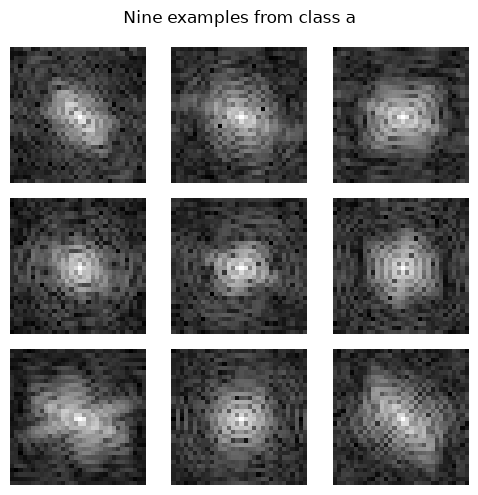

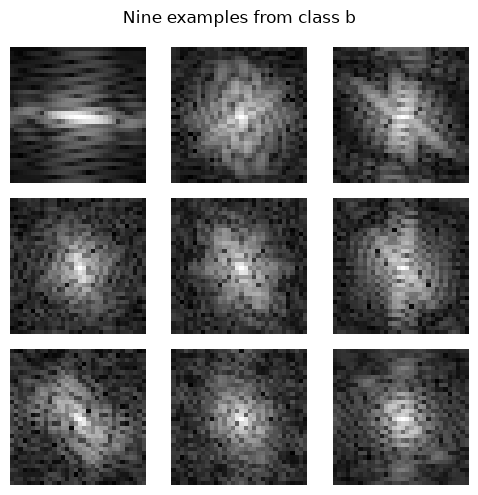

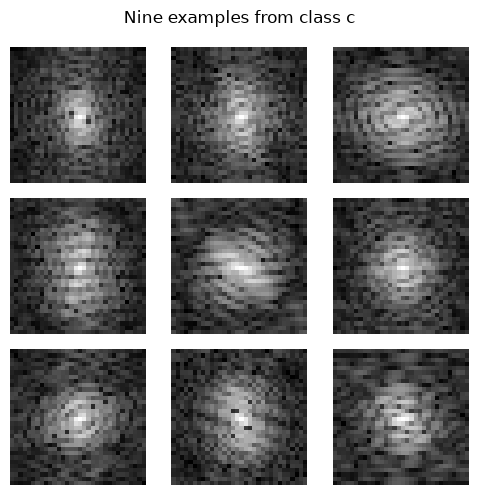

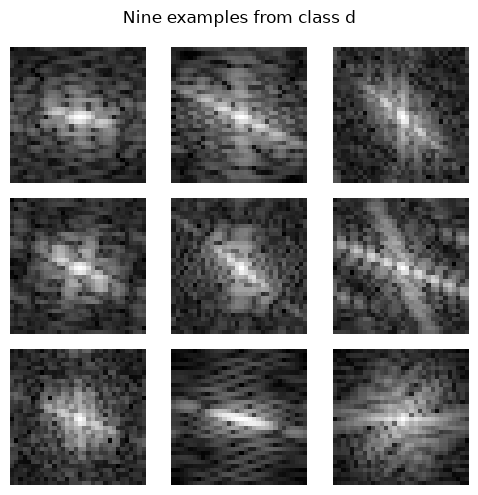

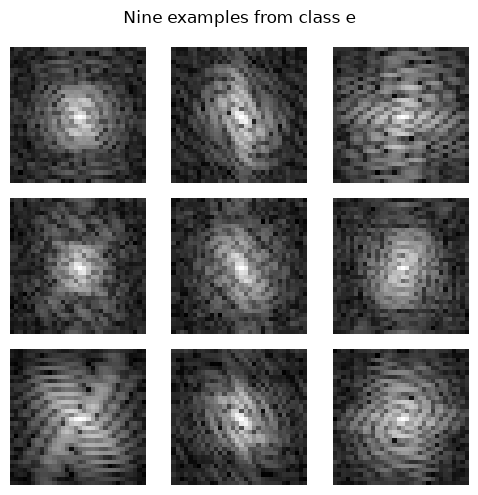

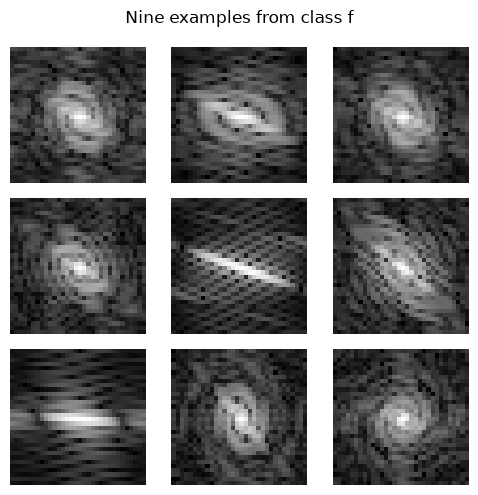

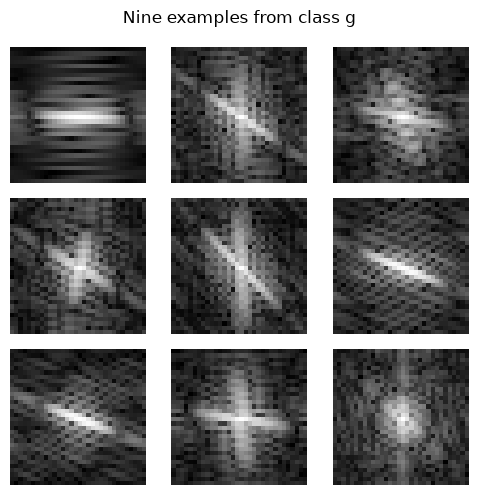

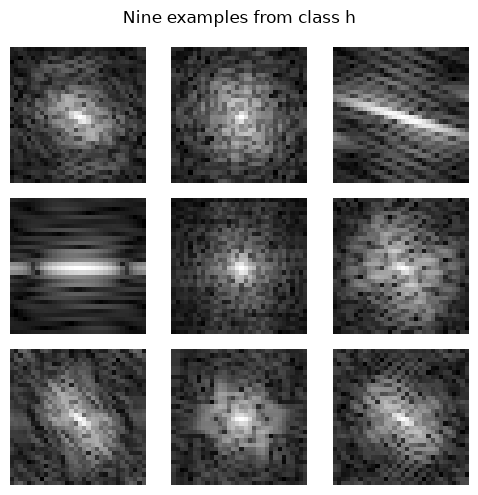

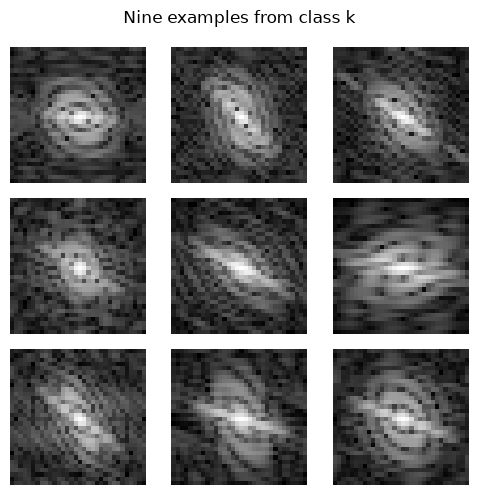

In [3]:
SEED = 42

rng = np.random.default_rng(SEED)
for label in class_names:
    candidate_indices = np.flatnonzero(labels == label)
    selected_indices = rng.choice(candidate_indices, size=9, replace=False)
    fig, axes = plt.subplots(3, 3, figsize=(5, 5))
    for ax, image_index in zip(axes.flat, selected_indices):
        ax.imshow(images[image_index], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(f"Nine examples from class {label}")
    fig.tight_layout()
    plt.show()


## Class distribution


The class counts range from 3,066 images for `e` (10.22%) to 3,492 images for `g` (11.64%). All nine classes are represented at similar frequencies, so the dataset has no substantial class imbalance.

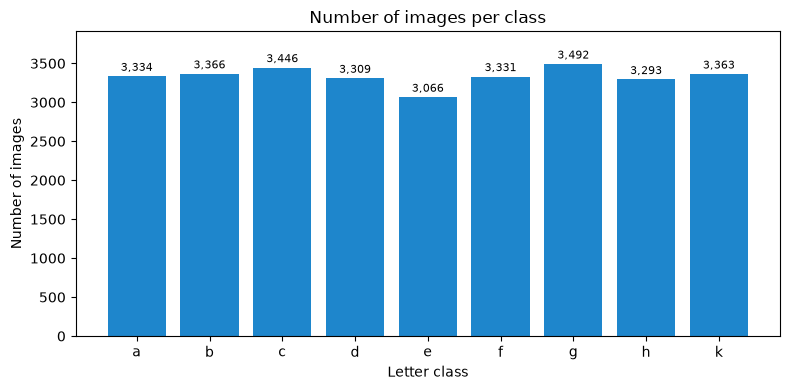

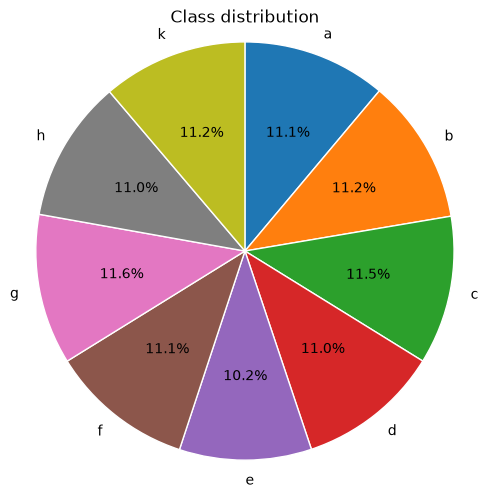

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_names, class_counts, color="#1e86cc")
ax.set_xlabel("Letter class")
ax.set_ylabel("Number of images")
ax.set_title("Number of images per class")
ax.set_ylim(0, max(class_counts) * 1.12)
for label, count in zip(class_names, class_counts):
    ax.text(label, count + 35, f"{count:,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(
    class_counts,
    labels=class_names,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 1},
)
ax.set_title("Class distribution")
ax.axis("equal")
fig.tight_layout()
plt.show()


## Exact duplicate images

All 30,000 images have distinct pixel arrays, so there are no exact duplicate groups or identical images with conflicting labels. This check does not detect near-duplicates or images that look similar after small changes.

In [22]:
flat_images = images.reshape(len(images), -1)
_, image_ids, copies_per_image = np.unique(
    flat_images, axis=0, return_inverse=True, return_counts=True
)
duplicate_ids = np.flatnonzero(copies_per_image > 1)
conflicting_ids = [
    image_id for image_id in duplicate_ids
    if np.unique(labels[image_ids == image_id]).size > 1
]

print(f"Total images: {len(images)}")
print(f"Distinct images: {len(copies_per_image)}")
print(f"Exact duplicate groups: {len(duplicate_ids)}")
print(f"Groups with conflicting labels: {len(conflicting_ids)}")


Total images: 30000
Distinct images: 30000
Exact duplicate groups: 0
Groups with conflicting labels: 0


# III. Validation and Preprocessing

# IV. Model Architecture

# V. Training Methodology

# VI. Experiments and Results

# VII. Evaluation and Error Analysis

# VIII. Reflection and Reproducibility

# IX. Sources and Acknowledgements